# Домашнее задание 3. Градиентный спуск, Ньютон, BFGS: реализация и сравнение

**Выдано:** 7 октября 2026. **Срок сдачи:** 21 октября 2026 (до начала занятия). **Максимум:** 10 баллов (+1 бонус).

**Как сдавать.** Заполните этот ноутбук (ответы на теоретические вопросы — в markdown-ячейках, формулы в $\LaTeX$; код — в code-ячейках), выполните целиком (`Kernel → Restart Kernel and Run All Cells`) и сдайте через pull request: файл `submissions/hw03/<фамилия>.ipynb`, инструкция — [`CONTRIBUTING.md`](../CONTRIBUTING.md). Задачи можно обсуждать, но текст и код пишутся самостоятельно.

**Материал:** лекция 4 ([конспект](../lectures/lecture04/lecture04.md)) и лекция 5 ([конспект](../lectures/lecture05/lecture05.md), [демо](../lectures/lecture05/demo05.ipynb), [семинар](../lectures/lecture05/seminar05.ipynb)). Ничего сверх лекций не требуется. Ориентировочное время — 3–4 часа.

**Устройство задания.** Обвязка — функции Розенброка, цепь, данные синуса, рисовальщики — дана готовой в ячейке ниже; вы пишете только то, что составляет метод: направление, выбор длины шага, обновление матрицы, шаг Гаусса–Ньютона. Под каждым заданием стоит проверка (`assert`), которая ловит смысл: если она прошла, можно идти дальше. Все методы работают с одними и теми же параметрами, чтобы числа совпали с конспектом: backtracking по Армихо с $c=10^{-4}$ от $\alpha=1$ делением пополам, останов по $\lVert\nabla f\rVert\le10^{-6}$ (у Ньютона — $10^{-10}$).

Запуск: `uv sync` в корне репозитория, затем `uv run jupyter lab`; в Colab ничего ставить не нужно.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize, least_squares

rng = np.random.default_rng(2026)

BLUE, ORANGE, AQUA, RED, VIOLET, GRAY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#4a3aa7", "#8a8985", "#0b0b0b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.2, "legend.frameon": False})



def rosen(x):
    return (1 - x[0]) ** 2 + 100 * (x[1] - x[0] ** 2) ** 2


def rosen_grad(x):
    return np.array([-2 * (1 - x[0]) - 400 * x[0] * (x[1] - x[0] ** 2), 200 * (x[1] - x[0] ** 2)])


def rosen_hess(x):
    return np.array([[2 - 400 * x[1] + 1200 * x[0] ** 2, -400 * x[0]], [-400 * x[0], 200.0]])


X0_ROSEN = np.array([-1.2, 1.0])


def make_chain(N, D=70.0, g=9.81):


    m = 4.0 / N
    K = 2 * np.eye(N) - np.eye(N, k=1) - np.eye(N, k=-1)
    H = np.kron(np.eye(2), D * K)
    b = np.zeros(2 * N)
    b[0] -= D * (-2.0); b[N - 1] -= D * 2.0; b[N] -= D * 1.0; b[2 * N - 1] -= D * 1.0; b[N:] += m * g
    v0 = np.r_[np.linspace(-2, 2, N + 2)[1:-1], np.ones(N)]

    def energy(v):
        y, z = np.r_[-2.0, v[:N], 2.0], np.r_[1.0, v[N:], 1.0]
        return 0.5 * D * np.sum(np.diff(y) ** 2 + np.diff(z) ** 2) + m * g * np.sum(z[1:-1])

    return energy, (lambda v: H @ v + b), H, b, v0



data_rng = np.random.default_rng(2026)
t_data = np.sort(data_rng.uniform(0, 2 * np.pi, 60))
y_data = 2.0 * np.sin(3.0 * t_data + 0.7) + 0.2 * data_rng.standard_normal(60)
starts = data_rng.uniform(-5, 5, (20, 3))
X0_SINE = np.array([1.0, 3.0, 0.0])


def sine_resid(x):

    return x[0] * np.sin(x[1] * t_data + x[2]) - y_data


def sine_jac(x):

    s, c = np.sin(x[1] * t_data + x[2]), np.cos(x[1] * t_data + x[2])
    return np.c_[s, x[0] * t_data * c, x[0] * c]


def sine_f(x):
    r = sine_resid(x); return 0.5 * (r @ r)


def sine_grad(x):
    return sine_jac(x).T @ sine_resid(x)



def plot_rosen_path(paths, labels=None, ax=None, xlim=(-2.2, 2.2), ylim=(-3.5, 3.2), every=50):

    if ax is None:
        _, ax = plt.subplots(figsize=(7, 5))
    X, Y = np.meshgrid(np.linspace(*xlim, 400), np.linspace(*ylim, 400))
    ax.contour(X, Y, (1 - X) ** 2 + 100 * (Y - X ** 2) ** 2, levels=np.logspace(-1, 3.3, 14), colors=[GRAY], linewidths=0.7)
    colors = [BLUE, ORANGE, AQUA, VIOLET, RED]
    for i, p in enumerate(paths):
        pp = p if len(p) <= 60 else np.r_[p[:30], p[30::every]]
        ax.plot(pp[:, 0], pp[:, 1], "-o", ms=3 if len(p) > 60 else 4.5, lw=1.3, color=colors[i % 5], label=None if labels is None else labels[i])
    ax.plot(1, 1, "*", ms=13, color=RED, mec="white", zorder=7)
    ax.set(xlim=xlim, ylim=ylim, xlabel="$x_1$", ylabel="$x_2$"); ax.grid(False)
    if labels is not None:
        ax.legend(loc="upper left", fontsize=8)
    return ax


def plot_grad_norms(gnorms, labels=None, ax=None):

    if ax is None:
        _, ax = plt.subplots(figsize=(6.5, 4.2))
    colors = [BLUE, ORANGE, AQUA, VIOLET, RED]
    for i, gn in enumerate(gnorms):
        ax.plot(np.arange(1, len(gn) + 1), np.log10(np.asarray(gn) + 1e-17), "-o" if len(gn) < 60 else "-", ms=3.5, lw=1.4, color=colors[i % 5], label=None if labels is None else labels[i])
    ax.set_xscale("log"); ax.set(xlabel="итерация $k$ (лог. шкала)", ylabel="$\\log_{10}\\Vert\\nabla f(x_k)\\Vert$")
    if labels is not None:
        ax.legend(fontsize=8)
    return ax


print("данные синуса:", t_data.shape, " стартов ДЗ 2:", len(starts), " f в старте (1, 3, 0):", round(sine_f(X0_SINE), 3))

данные синуса: (60,)  стартов ДЗ 2: 20  f в старте (1, 3, 0): 33.867


## Задача 1. Теория (4 балла)

По 1 баллу за пункт. Нужны выкладки, а не только ответ; численная проверка приветствуется, но текстом объясните, почему так.

**(а) Один шаг Ньютона.** $f(x)=x_1^2+2x_2^2+x_1x_2-4x_1-7x_2$. Из точки $x_0=(0,0)$ сделайте один шаг Ньютона руками: выпишите $\nabla f(x_0)$, $\nabla^2f$, решите систему $Hp=-g$ и проверьте, что в новой точке $\nabla f=0$. Почему здесь хватило одной итерации и какое свойство функции за это отвечает?

**(б) Цифры удваиваются.** Метод Ньютона для $F(x)=x^2-a$ даёт $x_{k+1}=\tfrac12(x_k+a/x_k)$. Покажите, что ошибка $e_k=x_k-\sqrt a$ удовлетворяет $e_{k+1}=\dfrac{e_k^2}{2x_k}$. Для $a=3$, $x_0=2$ выпишите $x_1,x_2,x_3$ и ошибки; сколько верных цифр прибавляет каждый шаг?

**(в) Секущее уравнение для $B$.** Обновление BFGS для самого гессиана (не обратного): $B_{k+1}=B_k-\dfrac{B_ks_ks_k^\top B_k}{s_k^\top B_ks_k}+\dfrac{y_ky_k^\top}{y_k^\top s_k}$. Проверьте подстановкой, что $B_{k+1}s_k=y_k$. Почему для этого нужно $y_k^\top s_k\ne0$, и что это условие означает для функции?

**(г) Что отбрасывает Гаусс–Ньютон.** $f(x)=\tfrac12\lVert r(x)\rVert^2$, $r(x)=\big(x_1-2,\ x_2-1,\ x_1x_2-1\big)$. Выпишите $J$, $J^\top J$ и полный гессиан $\nabla^2f=J^\top J+\sum_ir_i\nabla^2r_i$. Где отброшенный член равен нулю? Есть ли у этой задачи точка, где все невязки нулевые, и что это значит для сходимости Гаусса–Ньютона рядом с ней?

**(а)**

**Ответ:** Градиент и гессиан равны

$$
\nabla f(x)=\begin{pmatrix}2x_1+x_2-4\\x_1+4x_2-7\end{pmatrix},
\qquad g_0=\begin{pmatrix}-4\\-7\end{pmatrix},
\qquad H=\begin{pmatrix}2&1\\1&4\end{pmatrix}.
$$

Шаг Ньютона определяется системой

$$
Hp=-g_0\quad\Longleftrightarrow\quad
\begin{cases}2p_1+p_2=4,\\p_1+4p_2=7.\end{cases}
$$

Из $p_2=4-2p_1$ получаем $-7p_1=-9$, поэтому

$$
p=\left(\frac97,\frac{10}7\right)^\top,
\qquad x_1=x_0+p=\left(\frac97,\frac{10}7\right)^\top.
$$

Проверка:

$$
\nabla f(x_1)=
\begin{pmatrix}18/7+10/7-4\\9/7+40/7-7\end{pmatrix}
=\begin{pmatrix}0\\0\end{pmatrix}.
$$

Функция квадратична, поэтому её гессиан постоянен, а квадратичная модель Ньютона совпадает с самой функцией на всём пространстве. Кроме того, $H\succ0$ по критерию Сильвестра: $2>0$ и $\det H=7>0$, поэтому найденная стационарная точка — единственный глобальный минимум, $f(x_1)=-53/7$; полный шаг привёл бы к ней из любого старта.

In [2]:
H_quadratic = np.array([[2.0, 1.0], [1.0, 4.0]])
linear_quadratic = np.array([-4.0, -7.0])
x_start_quadratic = np.zeros(2)
step_quadratic = np.linalg.solve(H_quadratic, -(H_quadratic @ x_start_quadratic + linear_quadratic))
x_new_quadratic = x_start_quadratic + step_quadratic
print("Шаг Ньютона:", step_quadratic)
print("Новая точка:", x_new_quadratic)
print("Градиент в новой точке:", H_quadratic @ x_new_quadratic + linear_quadratic)
print("Собственные значения гессиана:", np.linalg.eigvalsh(H_quadratic))
assert np.allclose(x_new_quadratic, [9 / 7, 10 / 7])
assert np.linalg.norm(H_quadratic @ x_new_quadratic + linear_quadratic) < 1e-12

Шаг Ньютона: [1.28571429 1.42857143]
Новая точка: [1.28571429 1.42857143]
Градиент в новой точке: [0. 0.]
Собственные значения гессиана: [1.58578644 4.41421356]


**(б)**

**Ответ:** Пусть $a>0$, $x_k>0$ и $s=\sqrt a$. Тогда

$$
e_{k+1}=\frac12\left(x_k+\frac{s^2}{x_k}\right)-s
=\frac{x_k^2-2sx_k+s^2}{2x_k}
=\boxed{\frac{e_k^2}{2x_k}}.
$$

Для $a=3$, $x_0=2$:

$$
x_1=\frac74=1.75,\qquad
x_2=\frac{97}{56}\approx1.732142857142857,\qquad
x_3=\frac{18817}{10864}\approx1.732050810014728.
$$

При $\sqrt3\approx1.732050807568877$ ошибки составляют

$$
e_0\approx2.6794919243\cdot10^{-1},\quad
e_1\approx1.7949192431\cdot10^{-2},\quad
e_2\approx9.2049573980\cdot10^{-5},\quad
e_3\approx2.4458502470\cdot10^{-9}.
$$

Чтобы точно определить, что считаем цифрами, введём $d_k=-\log_{10}|e_k|$ — число десятичных порядков абсолютной точности. Получаем $d_0\approx0.572$, $d_1\approx1.746$, $d_2\approx4.036$, $d_3\approx8.612$: прибавки равны примерно $1.174$, $2.290$ и $4.576$ порядка, а не фиксированному числу цифр за шаг.

Из формулы ошибки следует $d_{k+1}=2d_k+\log_{10}(2x_k)$. При $x_k\to\sqrt3$ добавка стремится к $\log_{10}(2\sqrt3)\approx0.540$, поэтому точность асимптотически удваивается: сходимость квадратичная, $e_{k+1}/e_k^2\to1/(2\sqrt3)$. До округления машинной арифметики следующие шаги дают всё больше верных цифр.

In [3]:
from decimal import Decimal, localcontext

with localcontext() as decimal_context:
    decimal_context.prec = 60
    root_three = Decimal(3).sqrt()
    iterate = Decimal(2)
    previous_digits = None
    print(f"{'k':>2} {'x_k':>23} {'Ошибка':>16} {'-log10|e_k|':>14} {'Прибавка':>12}")
    for iteration in range(4):
        error = iterate - root_three
        digits = -abs(error).log10()
        increment = "—" if previous_digits is None else f"{digits - previous_digits:.6f}"
        print(f"{iteration:2d} {iterate:23.18f} {error:16.8E} {digits:14.6f} {increment:>12}")
        previous_digits = digits
        iterate = (iterate + Decimal(3) / iterate) / 2

 k                     x_k           Ошибка    -log10|e_k|     Прибавка
 0    2.000000000000000000    2.67949192E-1       0.571948            —
 1    1.750000000000000000    1.79491924E-2       1.745955     1.174008
 2    1.732142857142857143    9.20495740E-5       4.035978     2.290023
 3    1.732050810014727541    2.44585025E-9       8.611570     4.575592


**(в)**

**Ответ:** Опустим индекс $k$ и умножим обновление справа на $s$:

$$
B_+s
=Bs-\frac{Bs\,s^\top Bs}{s^\top Bs}
+\frac{y\,y^\top s}{y^\top s}
=Bs-Bs+y=y.
$$

Таким образом, секущее уравнение $B_{k+1}s_k=y_k$ выполнено. Для вычисления формулы нужны **оба** ненулевых знаменателя: $s^\top Bs\ne0$ и $y^\top s\ne0$; первый автоматически положителен при $B\succ0$ и $s\ne0$, второй относится к реальной кривизне функции вдоль шага.

Действительно, для $y=\nabla f(x+s)-\nabla f(x)$ при $f\in C^2$ имеем

$$
y^\top s=\int_0^1 s^\top\nabla^2f(x+ts)s\,dt.
$$

Условие $y^\top s\ne0$ означает ненулевую усреднённую кривизну вдоль пройденного отрезка; оно допускает и отрицательную кривизну, поэтому само по себе не гарантирует выпуклости. Для сохранения положительной определённости BFGS требуется более сильное условие $y^\top s>0$: на строго положительно определённой квадратичной функции оно выполнено при любом ненулевом шаге, а для общего случая его обеспечивает подходящий линейный поиск с условием кривизны Вольфе. Если $y^\top s=0$, записанная формула не определена и положительно определённая матрица не может одновременно удовлетворять $B_+s=y$ при $s\ne0$.

**(г)**

**Ответ:** Для заданных невязок

$$
J(x)=\begin{pmatrix}1&0\\0&1\\x_2&x_1\end{pmatrix},\qquad
J^\top J=
\begin{pmatrix}1+x_2^2&x_1x_2\\x_1x_2&1+x_1^2\end{pmatrix}.
$$

Первые две невязки аффинны, поэтому их гессианы нулевые, а

$$
\nabla^2r_3=\begin{pmatrix}0&1\\1&0\end{pmatrix}.
$$

Следовательно, отбрасываемая Гауссом–Ньютоном часть и полный гессиан равны

$$
S(x)=\sum_i r_i\nabla^2r_i
=(x_1x_2-1)\begin{pmatrix}0&1\\1&0\end{pmatrix},
$$
$$
\nabla^2f(x)=
\begin{pmatrix}1+x_2^2&2x_1x_2-1\\2x_1x_2-1&1+x_1^2\end{pmatrix}.
$$

Матрица $S(x)$ равна нулю **на гиперболе $x_1x_2=1$**, даже если первые две невязки не нулевые. Одновременно занулить все невязки невозможно: $r_1=r_2=0$ требует $x=(2,1)$, но в этой точке $r_3=1$.

Более того, стационарная точка не лежит на указанной гиперболе: при $r_3=0$ имеем $\nabla f=(x_1-2,x_2-1)^\top$, который обнулился бы только в противоречащей ей точке $(2,1)$. Поэтому в минимуме $S(x^*)\ne0$ и оснований ожидать квадратичную сходимость за счёт нулевых невязок нет; для этой задачи получается локальная линейная сходимость, что дополнительно проверяется ниже.

При полном шаге производная отображения Гаусса–Ньютона в стационарной точке равна $T'(x^*)=-(J^{*\top}J^*)^{-1}S(x^*)$: ненулевой отброшенный член создаёт линейный член ошибки. В найденном минимуме спектральный радиус этой матрицы меньше единицы и отличен от нуля; при нулевых невязках $S(x^*)=0$ этот линейный член исчез бы и при обычных условиях регулярности сходимость была бы квадратичной.

In [4]:
def example_residual(x):
    return np.array([x[0] - 2.0, x[1] - 1.0, x[0] * x[1] - 1.0])

def example_jacobian(x):
    return np.array([[1.0, 0.0], [0.0, 1.0], [x[1], x[0]]])

example_solution = least_squares(
    example_residual, np.array([2.0, 1.0]), jac=example_jacobian,
    ftol=1e-14, xtol=1e-14, gtol=1e-14,
)
example_x = example_solution.x
example_J = example_jacobian(example_x)
example_S = (example_x[0] * example_x[1] - 1.0) * np.array([[0.0, 1.0], [1.0, 0.0]])
example_H = example_J.T @ example_J + example_S
example_iteration_matrix = -np.linalg.solve(example_J.T @ example_J, example_S)
print("Найденный минимум:", example_x)
print("Невязки:", example_residual(example_x))
print("Норма градиента:", np.linalg.norm(example_J.T @ example_residual(example_x)))
print("Собственные значения полного гессиана:", np.linalg.eigvalsh(example_H))
print("Отброшенная матрица S:\n", example_S)
print("Спектральный радиус T'(x*):", np.max(np.abs(np.linalg.eigvals(example_iteration_matrix))))

Найденный минимум: [1.87666495 0.63616692]
Невязки: [-0.12333505 -0.36383308  0.19387216]
Норма градиента: 1.8856572699122737e-09
Собственные значения полного гессиана: [0.87642364 5.05015603]
Отброшенная матрица S:
 [[0.         0.19387216]
 [0.19387216 0.        ]]
Спектральный радиус T'(x*): 0.14616114082983248


## Задача 2. Практика (6 баллов)

### (а) Три кирпича методов (2 балла)

Метод Ньютона с backtracking и BFGS собираются из трёх частей; каждую пишете отдельно, под каждой — проверка. Сигнатуры не меняйте: ниже готовые циклы `newton_damped` и `bfgs` используют именно их.

**TODO 1 — направление Ньютона.** `newton_direction(g, H)` возвращает $p$ — решение $Hp=-g$. Если $g^\top p\ge0$ (направление не спуск — гессиан индефинитен), верните вместо него решение системы с регуляризованной матрицей $H+(\lvert\lambda_{\min}\rvert+10^{-3})I$.

In [5]:
def newton_direction(g, H):
    try:
        p = np.linalg.solve(H, -g)
        if g @ p < 0:
            return p
    except np.linalg.LinAlgError:
        pass
    smallest_eigenvalue = np.linalg.eigvalsh(H)[0]
    regularized_H = H + (abs(smallest_eigenvalue) + 1e-3) * np.eye(len(g))
    return np.linalg.solve(regularized_H, -g)

In [6]:
H_q = np.array([[2.0, 1.0], [1.0, 4.0]]); g_q = np.array([-4.0, -7.0])
assert np.allclose(newton_direction(g_q, H_q), [9 / 7, 10 / 7]), "на квадратичной 1(а) шаг Ньютона должен быть (9/7, 10/7): проверьте знак в решении системы"
H_ind = np.diag([1.0, -1.0]); g_ind = np.array([0.0, 1.0])
assert g_ind @ newton_direction(g_ind, H_ind) < 0, "при индефинитном H и g = (0, 1) чистый шаг (0, 1) идёт вверх — нужна регуляризация"
print("TODO 1: ok")

TODO 1: ok


**TODO 2 — длина шага по Армихо.** `armijo(f, x, p, g, c=1e-4)` возвращает $\alpha$: начинаем с $\alpha=1$ и делим пополам, пока не выполнено $f(x+\alpha p)\le f(x)+c\,\alpha\,g^\top p$ (лекция 4, §4.5; лекция 5, §3.4).

In [7]:
def armijo(f, x, p, g, c=1e-4):
    alpha = 1.0
    initial_value = f(x)
    directional_derivative = g @ p
    while True:
        trial_value = f(x + alpha * p)
        if np.isfinite(trial_value) and trial_value <= initial_value + c * alpha * directional_derivative:
            return alpha
        alpha *= 0.5
        if alpha == 0.0:
            raise RuntimeError("Не удалось подобрать положительный шаг по Армихо")

In [8]:
Q2 = np.diag([1.0, 10.0]); f2 = lambda x: 0.5 * x @ Q2 @ x
x2 = np.array([3.0, 1.0]); g2 = Q2 @ x2
a = armijo(f2, x2, -g2, g2)
assert abs(a - 0.125) < 1e-12, f"ожидался шаг 1/8, получен {a}: делите пополам, начиная с 1, и проверяйте условие с c * alpha * g^T p"
assert armijo(f2, x2, -g2 * 1e-3, g2) == 1.0, "короткое направление должно приниматься целиком (alpha = 1)"
print("TODO 2: ok")

TODO 2: ok


**TODO 3 — обновление BFGS.** `bfgs_update(H, s, y)` возвращает $H_{k+1}=(I-\rho sy^\top)H(I-\rho ys^\top)+\rho ss^\top$, $\rho=1/(y^\top s)$ (лекция 5, §4.3).

In [9]:
def bfgs_update(H, s, y):
    rho = 1.0 / (y @ s)
    identity = np.eye(len(s))
    left = identity - rho * np.outer(s, y)
    right = identity - rho * np.outer(y, s)
    return left @ H @ right + rho * np.outer(s, s)

In [10]:
Hs = np.eye(3); s_, y_ = np.array([1.0, -2.0, 0.5]), np.array([0.5, -1.0, 2.0])
Hn = bfgs_update(Hs, s_, y_)
assert np.allclose(Hn @ y_, s_), "секущее уравнение H_{k+1} y = s нарушено: проверьте порядок s и y в формуле"
assert np.allclose(Hn, Hn.T) and np.all(np.linalg.eigvalsh(Hn) > 0), "H_{k+1} должна быть симметричной и положительно определённой при s^T y > 0"
Q50 = np.diag([1.0, 50.0]); xq = np.array([50.0, 1.0]); Hq = np.eye(2)
for _ in range(2):
    gq = Q50 @ xq; pq = -Hq @ gq; aq = -(gq @ pq) / (pq @ Q50 @ pq)
    sq = aq * pq; xq = xq + sq; Hq = bfgs_update(Hq, sq, Q50 @ sq)
assert np.allclose(Hq, np.linalg.inv(Q50), atol=1e-10) and np.allclose(xq, 0, atol=1e-9), "после двух обновлений на квадратичной 2x2 должно получиться H_2 = Q^{-1} = diag(1, 0.02) и x_2 = 0"
print("TODO 3: ok;  H_2 =", Hq.round(6).tolist())

TODO 3: ok;  H_2 = [[1.0, -0.0], [0.0, 0.02]]


Сборка методов из кирпичей — дана готовой (сравните с лекцией: это ровно `newton_damped` и `bfgs` из `l5helpers.py`). `gd` — градиентный спуск с backtracking из лекции 4, тоже через ваш `armijo`.

In [11]:
def gd(f, grad, x0, alpha=None, tol=1e-6, maxit=100_000):

    x = np.asarray(x0, float).copy(); path = [x.copy()]; gnorm = []
    for k in range(maxit):
        g = grad(x); gnorm.append(np.linalg.norm(g))
        if gnorm[-1] <= tol:
            return x, k, np.array(path), np.array(gnorm)
        a = armijo(f, x, -g, g) if alpha is None else alpha
        x = x - a * g; path.append(x.copy())
    return x, maxit, np.array(path), np.array(gnorm)


def newton_damped(f, grad, hess, x0, tol=1e-10, maxit=200):

    x = np.asarray(x0, float).copy(); path = [x.copy()]; gnorm = []
    for k in range(maxit):
        g = grad(x); gnorm.append(np.linalg.norm(g))
        if gnorm[-1] <= tol:
            return x, k, np.array(path), np.array(gnorm)
        p = newton_direction(g, hess(x))
        x = x + armijo(f, x, p, g) * p; path.append(x.copy())
    return x, maxit, np.array(path), np.array(gnorm)


def bfgs(f, grad, x0, tol=1e-6, maxit=10_000):

    x = np.asarray(x0, float).copy(); H = np.eye(len(x)); g = grad(x); path = [x.copy()]; gnorm = [np.linalg.norm(g)]
    for k in range(maxit):
        if gnorm[-1] <= tol:
            return x, k, np.array(path), np.array(gnorm)
        p = -H @ g
        s = armijo(f, x, p, g) * p; x_new = x + s; g_new = grad(x_new); y = g_new - g
        if s @ y > 1e-12:
            H = bfgs_update(H, s, y)
        x, g = x_new, g_new; path.append(x.copy()); gnorm.append(np.linalg.norm(g))
    return x, maxit, np.array(path), np.array(gnorm)


print("методы собраны")

методы собраны


### (б) Розенброк и цепь: сравнение (2 балла)

1. Запустите три метода на Розенброке из $(-1.2,\,1)$ (спуск и BFGS — до $\lVert\nabla f\rVert\le10^{-6}$, Ньютон — до $10^{-10}$). Напечатайте таблицу: метод, число итераций, число вычислений $f$ (добавьте счётчик — например, обёрткой вокруг `rosen`), конечная точка. Ожидаемые числа конспекта — $13\,756$, $22$, $34$; расхождение до $5\,\%$ допустимо.
2. Нарисуйте две картинки готовыми рисовальщиками: пути трёх методов на линиях уровня (`plot_rosen_path`) и $\log_{10}\lVert\nabla f(x_k)\rVert$ по итерациям (`plot_grad_norms`). Назовите по графику тип сходимости каждого метода (лекция 4, §6; лекция 5, §3–4).
3. Цепь $N=40$: спуск с постоянным шагом $1/L$ ($L=\lambda_{\max}(H)$) против одного шага Ньютона `v0 - solve(H, grad(v0))`: число итераций, энергия в конце, расхождение решений. Затем запустите **ваш** `bfgs` на цепи $N=10$ и $N=20$ с `maxit=10_000`: сошёлся ли он? Объясните результат одним абзацем через §4.5 конспекта (что ломается у BFGS с одним лишь backtracking и что это лечит).

Критерии: полный балл — таблица с числами в пределах допуска, обе картинки, верно названные типы сходимости и внятное объяснение по цепи; половина — методы работают, но без анализа.

Метод                  Итераций   Вызовов f       ||∇f||₂              Конечная точка
Градиентный спуск         13756      150555   9.83337e-07   [0.999999219 0.999998434]
Ньютон с Армихо              22          51   0.00000e+00                     [1. 1.]
BFGS с Армихо                34          87   8.83463e-08   [0.999999995 0.99999999 ]


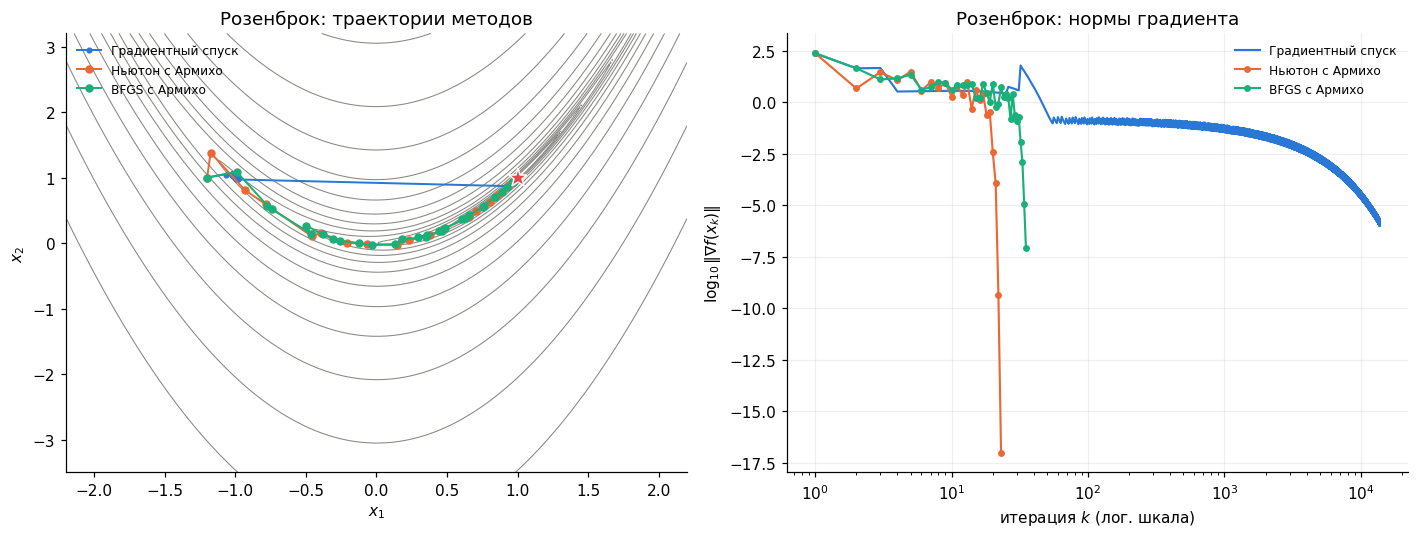

Градиентный спуск — последние отношения ошибок: [0.99921999 0.99921999 0.99921999 0.99921999 0.99921999]
Ньютон с Армихо — последние отношения ошибок: [5.39639446e-01 1.28830180e-01 1.27828370e-01 2.32384347e-03
 4.95492122e-05]
BFGS с Армихо — последние отношения ошибок: [0.1422179  0.30473541 0.01585011 0.03220823 0.01367585]


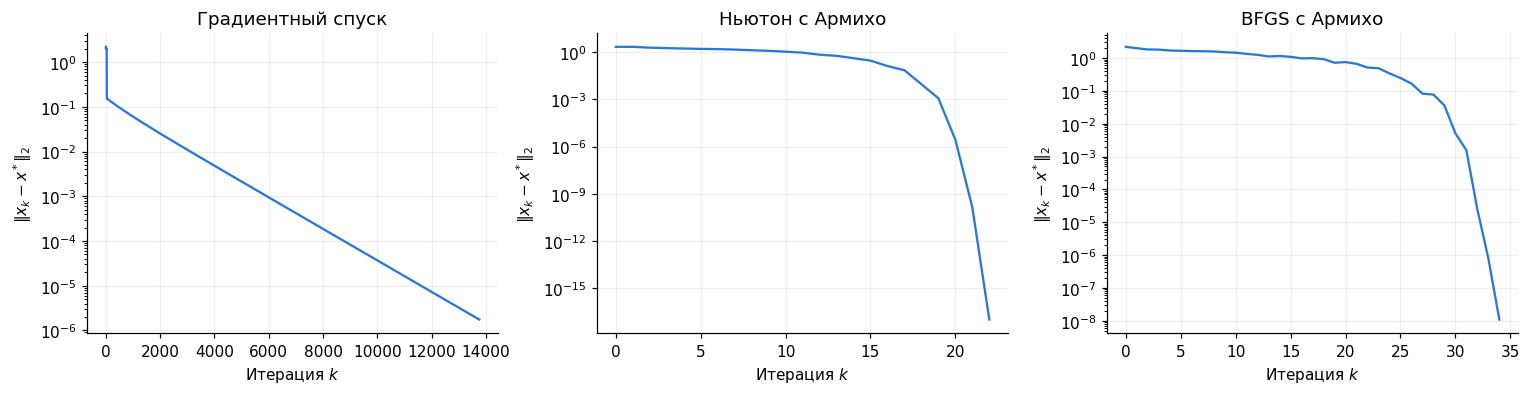

In [12]:
class CountedFunction:
    def __init__(self, function):
        self.function = function
        self.calls = 0

    def __call__(self, x):
        self.calls += 1
        return self.function(x)

rosen_runs = {}
rosen_function_calls = {}
for label, solver in [
    ("Градиентный спуск", lambda f: gd(f, rosen_grad, X0_ROSEN, tol=1e-6)),
    ("Ньютон с Армихо", lambda f: newton_damped(f, rosen_grad, rosen_hess, X0_ROSEN, tol=1e-10)),
    ("BFGS с Армихо", lambda f: bfgs(f, rosen_grad, X0_ROSEN, tol=1e-6)),
]:
    counted_objective = CountedFunction(rosen)
    rosen_runs[label] = solver(counted_objective)
    rosen_function_calls[label] = counted_objective.calls

print(f"{'Метод':<21} {'Итераций':>9} {'Вызовов f':>11} {'||∇f||₂':>13} {'Конечная точка':>27}")
for label, (point, iterations, path, norms) in rosen_runs.items():
    print(f"{label:<21} {iterations:9d} {rosen_function_calls[label]:11d} "
          f"{np.linalg.norm(rosen_grad(point)):13.5e} {np.array2string(point, precision=9):>27}")

labels_rosen = list(rosen_runs)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_rosen_path([result[2] for result in rosen_runs.values()], labels_rosen, ax=axes[0])
plot_grad_norms([result[3] for result in rosen_runs.values()], labels_rosen, ax=axes[1])
axes[0].set_title("Розенброк: траектории методов")
axes[1].set_title("Розенброк: нормы градиента")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.7))
for axis, (label, result) in zip(axes, rosen_runs.items()):
    errors = np.linalg.norm(result[2] - np.ones(2), axis=1)
    axis.semilogy(np.arange(len(errors)), np.maximum(errors, 1e-17), color=BLUE)
    axis.set(title=label, xlabel="Итерация $k$", ylabel=r"$\|x_k-x^*\|_2$")
    positive = (errors[:-1] > 1e-13) & (errors[1:] > 1e-13)
    ratios = errors[1:][positive] / errors[:-1][positive]
    print(label, "— последние отношения ошибок:", ratios[-5:])
fig.tight_layout()
plt.show()

**Ответ:** На Розенброке получены следующие результаты; $x^*=(1,1)^\top$.

| Метод | Итераций | Вызовов $f$ | Итоговая $\|\nabla f\|_2$ |
|---|---:|---:|---:|
| Градиентный спуск, Армихо | 13 756 | 150 555 | $9.83\cdot10^{-7}$ |
| Демпфированный Ньютон | 22 | 51 | $0$ в машинной арифметике |
| BFGS, Армихо | 34 | 87 | $8.83\cdot10^{-8}$ |

Числа итераций совпали с конспектом; конечные точки напечатаны над графиками. Счётчик учитывает **каждый реальный вызов функции внутри метода**, включая повторные вычисления $f(x_k)$ в начале линейного поиска; вычисления для итогового отчёта, градиента и графиков не учитываются. Поэтому для BFGS получилось 87 вызовов, а не 54 из конспекта: здесь 34 вычисления в текущей точке и 53 в пробных точках; при повторном использовании уже принятого значения вместо нового вычисления в текущей точке хватило бы $1+53=54$.

Градиентный спуск движется медленно вдоль узкой долины и имеет **линейную сходимость**: последние отношения ошибок $\|e_{k+1}\|/\|e_k\|$ близки к $0.99922$. У Ньютона после попадания в окрестность минимума принимаются полные шаги и наблюдается **квадратичная локальная сходимость**, $\|e_{k+1}\|=O(\|e_k\|^2)$; у BFGS — характерное для **сверхлинейной сходимости** ускорение, когда отношение ошибок стремится к нулю, но без обязательного квадратичного закона. Это локальная интерпретация эксперимента, а не доказательство асимптотики по конечному набору точек; конечные цифры ограничены округлением.

У готового графика норм градиента ось итераций логарифмическая, поэтому правило «прямая означает линейную сходимость» к нему напрямую неприменимо. Для проверки добавлены графики $\|x_k-x^*\|_2$ с логарифмической вертикальной и **линейной горизонтальной** шкалами, а также отношения ошибок; норма градиента на отдельных шагах может расти, хотя Армихо обеспечивает уменьшение самой цели.

На цепи $N=40$ имеем $L\approx279.5892$, $\mu\approx0.41079$, $\kappa=L/\mu\approx680.62$. Спуск с шагом $1/L$ достиг допуска за **10 575 итераций**, а Ньютон — за **одну**: квадратичная модель здесь точна. Обе энергии равны примерно $13.44173558537$, расстояние между решениями составляет $2.43\cdot10^{-6}$; небольшое ненулевое расстояние согласуется с остановом спуска по градиенту, поскольку $\|v-v^*\|\le\|\nabla E(v)\|/\mu$.

У BFGS с одним Армихо для $N=10$ получилось **27 итераций** и $\|\nabla E\|\approx4.66\cdot10^{-8}$, а при $N=20$ после **10 000 итераций** осталось $\|\nabla E\|\approx3.15\cdot10^{-6}>10^{-6}$: останов по требуемому допуску не достигнут. Как объясняется в §4.5, достаточное убывание Армихо само по себе не контролирует качество информации о кривизне: чрезмерно короткие шаги дают малые и чувствительные к округлению пары $(s,y)$, обновления могут пропускаться из-за порога $s^\top y>10^{-12}$, а около минимума сравнение почти одинаковых значений энергии становится неточным. Это возможно и на строго выпуклой квадратичной задаче; зависимость от округления объясняет отличие 27 от 42 итераций в примере конспекта для $N=10$. Линейный поиск с условиями Вольфе дополнительно контролирует изменение направленной производной, улучшает пары кривизны и является существенной частью устойчивого BFGS; на квадратичной функции также помогает точный линейный поиск. Простая проверка $s^\top y>0$ сохраняет положительную определённость в точной арифметике, но не заменяет эти требования к качеству шага.

In [13]:
chain_energy, chain_gradient, chain_H, chain_b, chain_start = make_chain(40)
chain_eigenvalues = np.linalg.eigvalsh(chain_H)
chain_L = chain_eigenvalues[-1]
chain_gd = gd(chain_energy, chain_gradient, chain_start, alpha=1.0 / chain_L, tol=1e-6)
chain_newton = chain_start - np.linalg.solve(chain_H, chain_gradient(chain_start))
print(f"Цепь N = 40: L = {chain_L:.8f}, μ = {chain_eigenvalues[0]:.8f}, κ = {chain_L / chain_eigenvalues[0]:.4f}")
print(f"Спуск: {chain_gd[1]} итераций, E = {chain_energy(chain_gd[0]):.12f}, "
      f"||∇E||₂ = {np.linalg.norm(chain_gradient(chain_gd[0])):.3e}")
print(f"Ньютон: 1 итерация, E = {chain_energy(chain_newton):.12f}, "
      f"||∇E||₂ = {np.linalg.norm(chain_gradient(chain_newton)):.3e}")
print(f"Расхождение решений: {np.linalg.norm(chain_gd[0] - chain_newton):.6e}")

chain_bfgs_runs = {}
print(f"\n{'N':>3} {'Итераций':>10} {'||∇E||₂':>14} {'Сошёлся':>10} {'Ошибка решения':>18}")
for chain_size in [10, 20]:
    energy, gradient, hessian, linear_term, initial = make_chain(chain_size)
    result = bfgs(energy, gradient, initial, tol=1e-6, maxit=10_000)
    chain_bfgs_runs[chain_size] = result
    gradient_norm = np.linalg.norm(gradient(result[0]))
    exact = np.linalg.solve(hessian, -linear_term)
    print(f"{chain_size:3d} {result[1]:10d} {gradient_norm:14.6e} "
          f"{str(gradient_norm <= 1e-6):>10} {np.linalg.norm(result[0] - exact):18.6e}")

Цепь N = 40: L = 279.58921217, μ = 0.41078783, κ = 680.6171
Спуск: 10575 итераций, E = 13.441735585367, ||∇E||₂ = 9.988e-07
Ньютон: 1 итерация, E = 13.441735585366, ||∇E||₂ = 1.878e-13
Расхождение решений: 2.431473e-06

  N   Итераций        ||∇E||₂    Сошёлся     Ошибка решения
 10         27   4.664470e-08       True       2.452578e-10


 20      10000   3.154575e-06      False       6.040130e-08


### (в) Гаусс–Ньютон на синусе из ДЗ 2 (2 балла)

**TODO 4 — шаг Гаусса–Ньютона.** Допишите в `gauss_newton` строку с направлением: $p$ — решение линейного МНК $\min_p\lVert Jp+r\rVert^2$ (`np.linalg.lstsq`). Длина шага — ваш `armijo` на $f=\tfrac12\lVert r\rVert^2$ (демпфированный Гаусс–Ньютон). Проверка под ячейкой: на **линейных** невязках $r=Ax-b$ метод обязан сойтись за одну итерацию к `lstsq`.

Затем:

1. Запустите из $(1,\,3,\,0)$: ожидается $7$ итераций и $f^\ast=1.1393$, $x^\ast\approx(2.10,\,2.997,\,0.700)$. Сравните с вашим `bfgs` на `sine_f` из того же старта (итерации и вызовы функции) и со спуском ($731$ итерация в конспекте).
2. Запустите из всех 20 стартов `starts` ДЗ 2 (`maxit=200`). Сколько стартов пришли к глобальному $f^\ast=1.1393$ (с точностью $10^{-6}$)? Нарисуйте данные и все 20 подогнанных кривых одной картинкой. Объясните в двух предложениях, почему быстрый локальный метод не отменяет мультистарт из ДЗ 2.

Критерии: полный балл — проверка на линейных невязках проходит, числа пункта 1 воспроизведены, картинка и объяснение; половина — метод сходится, но без сравнения или без мультистарта.

In [14]:
def gauss_newton(resid, jac, x0, tol=1e-6, maxit=100):

    f = lambda x: 0.5 * np.sum(resid(x) ** 2)
    x = np.asarray(x0, float).copy(); path = [x.copy()]; gnorm = []
    for k in range(maxit):
        r, J = resid(x), jac(x); g = J.T @ r; gnorm.append(np.linalg.norm(g))
        if gnorm[-1] <= tol:
            return x, k, np.array(path), np.array(gnorm)
        p = np.linalg.lstsq(J, -r, rcond=None)[0]
        x = x + armijo(f, x, p, g) * p; path.append(x.copy())
    return x, maxit, np.array(path), np.array(gnorm)

In [15]:
A_lin = rng.standard_normal((30, 4)); b_lin = rng.standard_normal(30)
x_lin, k_lin, _, _ = gauss_newton(lambda x: A_lin @ x - b_lin, lambda x: A_lin, np.ones(4), tol=1e-10)
assert k_lin == 1 and np.allclose(x_lin, np.linalg.lstsq(A_lin, b_lin, rcond=None)[0]), "на линейных невязках Гаусс–Ньютон должен совпасть с lstsq за одну итерацию: проверьте знак (-r) и что p решает именно min ||J p + r||"
print("TODO 4: ok")

TODO 4: ok


Метод                  Итераций   Вызовов f       f в конце       ||∇f||₂
Гаусс–Ньютон                  7          14    1.1392730978   3.18836e-07
  x = [2.101392533 2.996690619 0.70026397 ]
BFGS                         12          41    1.1392730978   1.30724e-07
  x = [2.101392532 2.996690622 0.700263959]
Градиентный спуск           745        8870    1.1392730978   4.17066e-07
  x = [2.101392531 2.99669062  0.700263964]



Опорное значение без округления: 1.139273097803


Старт  Итераций                f       ||∇f||₂   Близко к f*    Сошёлся
    1         8     1.1392730978   5.60916e-08          True       True
    2       128     1.1392730978   3.15856e-07          True       True
    3         9     1.1392730978   1.02363e-07          True       True
    4         7     1.1392730978   2.42445e-08          True       True
    5         7     1.1392730978   3.67633e-07          True       True
    6        31    61.4972734409   4.25143e-07         False       True
    7       103    61.6881706781   7.05952e-08         False       True
    8        12     1.1392730978   4.76872e-08          True       True
    9         7     1.1392730978   3.03473e-07          True       True
   10        12     1.1392730978   2.29303e-07          True       True
   11        28    60.1414429535   6.71710e-07         False       True
   12        10     1.1392730978   1.76468e-07          True       True
   13        29    61.4972734409   7.45212e-07         False   

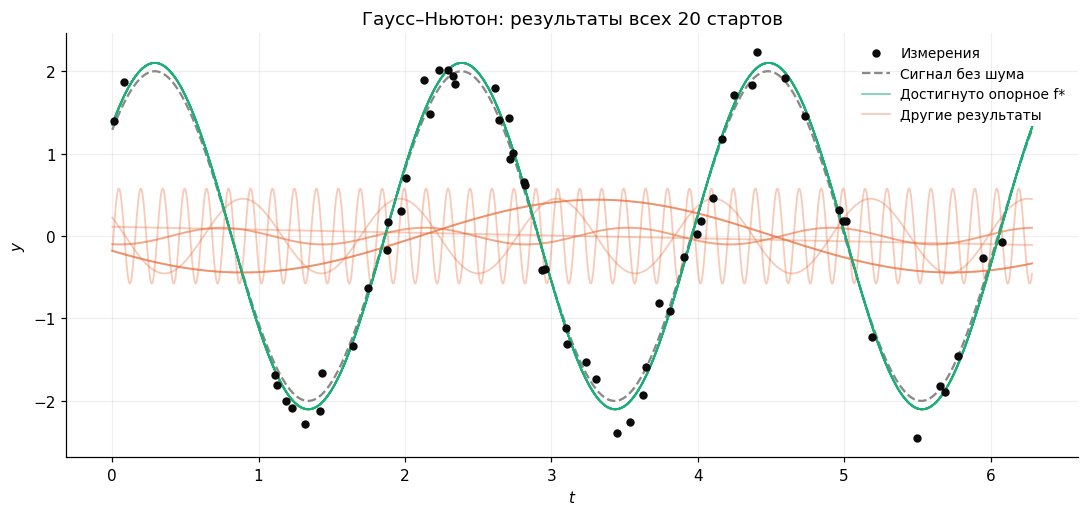

In [16]:
sine_runs = {}
sine_function_calls = {}
counted_residual = CountedFunction(sine_resid)
sine_runs["Гаусс–Ньютон"] = gauss_newton(counted_residual, sine_jac, X0_SINE)
sine_function_calls["Гаусс–Ньютон"] = counted_residual.calls - len(sine_runs["Гаусс–Ньютон"][3])
for label, method in [("BFGS", bfgs), ("Градиентный спуск", gd)]:
    counted_objective = CountedFunction(sine_f)
    sine_runs[label] = method(counted_objective, sine_grad, X0_SINE, tol=1e-6)
    sine_function_calls[label] = counted_objective.calls

print(f"{'Метод':<21} {'Итераций':>9} {'Вызовов f':>11} {'f в конце':>15} {'||∇f||₂':>13}")
for label, result in sine_runs.items():
    print(f"{label:<21} {result[1]:9d} {sine_function_calls[label]:11d} "
          f"{sine_f(result[0]):15.10f} {np.linalg.norm(sine_grad(result[0])):13.5e}")
    print("  x =", np.array2string(result[0], precision=9))

sine_reference = least_squares(sine_resid, sine_runs["Гаусс–Ньютон"][0], jac=sine_jac,
                               ftol=1e-13, xtol=1e-13, gtol=1e-13)
sine_reference_value = sine_f(sine_reference.x)
multistart_gn = [gauss_newton(sine_resid, sine_jac, start, maxit=200) for start in starts]
multistart_values = np.array([sine_f(result[0]) for result in multistart_gn])
multistart_norms = np.array([np.linalg.norm(sine_grad(result[0])) for result in multistart_gn])
reached_reference = np.isclose(multistart_values, sine_reference_value, atol=1e-6, rtol=0.0)
print(f"\nОпорное значение без округления: {sine_reference_value:.12f}")
print(f"{'Старт':>5} {'Итераций':>9} {'f':>16} {'||∇f||₂':>13} {'Близко к f*':>13} {'Сошёлся':>10}")
for index, result in enumerate(multistart_gn):
    print(f"{index + 1:5d} {result[1]:9d} {multistart_values[index]:16.10f} "
          f"{multistart_norms[index]:13.5e} {str(reached_reference[index]):>13} "
          f"{str(multistart_norms[index] <= 1e-6):>10}")
print(f"Пришли к опорному значению: {reached_reference.sum()}/20 = {reached_reference.mean():.0%}")
print("Из них удовлетворяют останову по градиенту:",
      np.count_nonzero(reached_reference & (multistart_norms <= 1e-6)))

time_grid = np.linspace(0, 2 * np.pi, 1600)
fig, axis = plt.subplots(figsize=(10, 4.8))
axis.scatter(t_data, y_data, color=INK, s=20, zorder=5, label="Измерения")
axis.plot(time_grid, 2 * np.sin(3 * time_grid + 0.7), "--", color=GRAY, label="Сигнал без шума")
seen_groups = set()
for index, result in enumerate(multistart_gn):
    group = "Достигнуто опорное f*" if reached_reference[index] else "Другие результаты"
    parameters = result[0]
    prediction = parameters[0] * np.sin(parameters[1] * time_grid + parameters[2])
    axis.plot(time_grid, prediction, color=AQUA if reached_reference[index] else ORANGE,
              alpha=0.55 if reached_reference[index] else 0.35, linewidth=1.2,
              label=group if group not in seen_groups else None)
    seen_groups.add(group)
axis.set(xlabel="$t$", ylabel="$y$", title="Гаусс–Ньютон: результаты всех 20 стартов")
axis.legend(loc="upper right", fontsize=9)
fig.tight_layout()
plt.show()

**Ответ:** На линейных невязках встроенная проверка прошла: решение линейного МНК найдено за одну итерацию. Для синуса из старта $(1,3,0)$ получено

$$
x^*\approx(2.10139253,\ 2.99669062,\ 0.70026397)^\top,
\qquad f(x^*)\approx1.139273097803.
$$

| Метод | Итераций | Вызовов $f$ | Итоговая $\|\nabla f\|_2$ |
|---|---:|---:|---:|
| Гаусс–Ньютон | 7 | 14 | $3.19\cdot10^{-7}$ |
| BFGS | 12 | 41 | $1.31\cdot10^{-7}$ |
| Градиентный спуск | 745 | 8 870 | $4.17\cdot10^{-7}$ |

Все три метода пришли к одному значению цели. Гаусс–Ньютон воспроизвёл 7 итераций из задания; у спуска в данной среде получилось 745 вместо 731, то есть примерно на $1.9\%$ больше, при том же старте, допуске и правиле Армихо. Это фактическое число, а не замена результата числом из конспекта; около минимума решения о принятии шага чувствительны к погрешности вычисления почти одинаковых значений функции.

В счётчик включены текущие и пробные значения цели, но не отдельные вычисления градиента и Якобиана. Для Гаусса–Ньютона число вызовов цели получено из числа вычислений невязок вычитанием одного вызова на каждую записанную норму градиента: эти вызовы служат построению $r,J,g$, а остальные вычисляют $\tfrac12\|r\|^2$ при поиске шага; стоимость одной итерации дополнительно включает решение линейного МНК.

Из 20 стартов **12 достигли опорного значения ($60\%$)** с абсолютной точностью $10^{-6}$ и одновременно выполнили условие $\|\nabla f\|_2\le10^{-6}$. Сравнение проведено с уточнённым значением $1.139273097803$, а не с округлённым $1.1393$: само это округление отличается от минимума примерно на $2.69\cdot10^{-5}$, что больше допуска. Всего останов по градиенту достигнут в 19 запусках; старт 19 исчерпал 200 итераций, поэтому его последняя точка не объявляется решением.

Быстрая сходимость Гаусса–Ньютона локальна: она помогает внутри подходящей области притяжения, но не устраняет невыпуклость подгонки по неизвестной частоте и фазе. Поэтому разные старты могут приводить к разным стационарным точкам или не успеть сойтись, и мультистарт остаётся полезным, хотя сам по себе не доказывает глобальность лучшего результата.

## Бонус (+1 балл). L-BFGS своими руками

Реализуйте L-BFGS с памятью $m=5$: храните последние $m$ пар $(s_i,y_i)$ и вычисляйте $p=-H_kg$ двухпроходной рекурсией (*two-loop recursion*, Nocedal & Wright, алгоритм 7.4) с начальной матрицей $\gamma_kI$, $\gamma_k=s^\top y/y^\top y$ по последней паре; длина шага — ваш `armijo`. Запустите на цепи $N=40$ и сравните с `scipy.optimize.minimize(method="L-BFGS-B", options={"maxcor": 5})` по числу итераций (у SciPy — $75$) и с `np.linalg.solve` по времени; объясните, почему ваш вариант делает больше итераций (подсказка: §4.5 конспекта). Балл — за работающую рекурсию (проверка: на квадратичной $2\times2$ при $m\ge2$ после двух шагов направление совпадает с ньютоновским) и честное сравнение.

In [17]:
from time import perf_counter

def lbfgs_direction(g, pairs):
    q = np.asarray(g, float).copy()
    coefficients = []
    for s, y in reversed(pairs):
        rho = 1.0 / (y @ s)
        alpha = rho * (s @ q)
        coefficients.append((alpha, rho))
        q -= alpha * y
    gamma = 1.0
    if pairs:
        last_s, last_y = pairs[-1]
        gamma = (last_s @ last_y) / (last_y @ last_y)
    r = gamma * q
    for (s, y), (alpha, rho) in zip(pairs, reversed(coefficients)):
        beta = rho * (y @ r)
        r += s * (alpha - beta)
    return -r

def lbfgs(f, grad, x0, m=5, tol=1e-6, maxit=10_000):
    x = np.asarray(x0, float).copy()
    g = grad(x)
    pairs = []
    path = [x.copy()]
    norms = [np.linalg.norm(g)]
    for iteration in range(maxit):
        if norms[-1] <= tol:
            return x, iteration, np.array(path), np.array(norms)
        direction = lbfgs_direction(g, pairs)
        step = armijo(f, x, direction, g) * direction
        next_x = x + step
        next_g = grad(next_x)
        difference = next_g - g
        if step @ difference > 1e-12:
            pairs.append((step.copy(), difference.copy()))
            pairs = pairs[-m:]
        x, g = next_x, next_g
        path.append(x.copy())
        norms.append(np.linalg.norm(g))
    return x, maxit, np.array(path), np.array(norms)

test_Q = np.diag([1.0, 50.0])
test_x = np.array([50.0, 1.0])
test_pairs = []
for iteration in range(2):
    test_g = test_Q @ test_x
    test_p = lbfgs_direction(test_g, test_pairs)
    test_alpha = -(test_g @ test_p) / (test_p @ test_Q @ test_p)
    test_s = test_alpha * test_p
    test_pairs.append((test_s.copy(), test_Q @ test_s))
    test_x = test_x + test_s
probe_gradient = np.array([2.0, -3.0])
assert np.allclose(test_x, np.zeros(2), atol=1e-9)
assert np.allclose(lbfgs_direction(probe_gradient, test_pairs),
                   -np.linalg.solve(test_Q, probe_gradient), atol=1e-10)
assert np.allclose(lbfgs_direction(test_Q @ test_x, test_pairs), -test_x, atol=1e-10)
print("Двухпроходная рекурсия: проверки на квадратичной 2×2 пройдены")

def timed_run(function, repeats=3):
    durations = []
    for repeat in range(repeats):
        started = perf_counter()
        result = function()
        durations.append(perf_counter() - started)
    return result, float(np.median(durations))

own_lbfgs, own_lbfgs_seconds = timed_run(
    lambda: lbfgs(chain_energy, chain_gradient, chain_start, m=5, tol=1e-6)
)
scipy_lbfgs, scipy_lbfgs_seconds = timed_run(
    lambda: minimize(chain_energy, chain_start, jac=chain_gradient, method="L-BFGS-B",
                     options={"maxcor": 5, "gtol": 1e-6, "maxiter": 10_000})
)
direct_solution, direct_seconds = timed_run(lambda: np.linalg.solve(chain_H, -chain_b), repeats=21)
scipy_strict, scipy_strict_seconds = timed_run(
    lambda: minimize(chain_energy, chain_start, jac=chain_gradient, method="L-BFGS-B",
                     options={"maxcor": 5, "gtol": 1e-6 / np.sqrt(chain_start.size),
                              "ftol": 0.0, "maxiter": 10_000, "maxls": 50})
)

print(f"\n{'Метод':<26} {'Итераций':>9} {'Время, мс':>12} {'||∇E||₂':>13} {'Ошибка решения':>16}")
for label, point, iterations, duration in [
    ("L-BFGS свой, Армихо", own_lbfgs[0], own_lbfgs[1], own_lbfgs_seconds),
    ("SciPy, настройки лекции", scipy_lbfgs.x, scipy_lbfgs.nit, scipy_lbfgs_seconds),
    ("SciPy, строгий останов", scipy_strict.x, scipy_strict.nit, scipy_strict_seconds),
    ("np.linalg.solve", direct_solution, 1, direct_seconds),
]:
    print(f"{label:<26} {iterations:9d} {duration * 1000:12.4f} "
          f"{np.linalg.norm(chain_gradient(point)):13.5e} {np.linalg.norm(point - direct_solution):16.5e}")
print("Свой L-BFGS достиг ||∇E||₂ ≤ 1e-6:", np.linalg.norm(chain_gradient(own_lbfgs[0])) <= 1e-6)
print("SciPy, настройки лекции:", scipy_lbfgs.success, scipy_lbfgs.message)
print("SciPy, строгий останов:", scipy_strict.success, scipy_strict.message)

Двухпроходная рекурсия: проверки на квадратичной 2×2 пройдены



Метод                       Итераций    Время, мс       ||∇E||₂   Ошибка решения
L-BFGS свой, Армихо              145      22.3431   9.97564e-07      1.23778e-06
SciPy, настройки лекции           75       4.8830   8.21870e-04      2.41352e-04
SciPy, строгий останов           141       7.5937   7.96003e-07      4.49343e-07
np.linalg.solve                    1       0.0391   1.40939e-13      0.00000e+00
Свой L-BFGS достиг ||∇E||₂ ≤ 1e-6: True
SciPy, настройки лекции: True CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
SciPy, строгий останов: True CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH


**Ответ:** Реализована двухпроходная рекурсия с хранением не более $m=5$ пар: в первом проходе от новой пары к старой вычисляются $\alpha_i=\rho_i s_i^\top q$ и $q\leftarrow q-\alpha_i y_i$, затем применяется масштаб $r=\gamma_kq$, а во втором проходе от старой пары к новой — $\beta_i=\rho_i y_i^\top r$ и $r\leftarrow r+s_i(\alpha_i-\beta_i)$. Здесь $\rho_i=(y_i^\top s_i)^{-1}$, $\gamma_k=s_{k-1}^\top y_{k-1}/(y_{k-1}^\top y_{k-1})$, а направление равно $p=-r$; до накопления пар используется $\gamma_0=1$. При $s^\top y\le10^{-12}$ пара пропускается, как в заданном BFGS, чтобы не делить на слишком малую кривизну.

Проверка на квадратичной функции с $Q=\operatorname{diag}(1,50)$ пройдена: после двух шагов с **точным линейным поиском** сохранённые пары восстанавливают действие $Q^{-1}$. Для содержательной проверки направление сравнивается с $-Q^{-1}g$ также на независимом ненулевом векторе $g=(2,-3)^\top$, поскольку в уже достигнутом минимуме оба направления были бы нулевыми независимо от качества матрицы. Конечность за два шага относится к этому тесту с точным поиском; на цепи, как требует задание, используется Армихо.

На цепи $N=40$ получено:

| Метод | Итераций | Фактическая $\|\nabla E\|_2$ | Время, мс |
|---|---:|---:|---:|
| Свой L-BFGS, $m=5$, Армихо | 145 | $9.98\cdot10^{-7}$ | $\approx22.34$ |
| SciPy L-BFGS-B, настройки конспекта | 75 | $8.22\cdot10^{-4}$ | $\approx4.88$ |
| SciPy L-BFGS-B, более строгие настройки | 141 | $7.96\cdot10^{-7}$ | $\approx7.59$ |
| Решение системы через np.linalg.solve | 1 | $1.41\cdot10^{-13}$ | $\approx0.039$ |

Времена — медианы трёх запусков методов и 21 решения системы с уже построенными данными; они зависят от машины и нагрузки, а число итераций не равно вычислительной стоимости. В этой задаче из 80 переменных решение линейной системы быстрее и точнее итерационных методов.

Сравнение **145 против 75** нельзя целиком объяснять линейным поиском: SciPy с настройками конспекта остановился по малому относительному изменению энергии, не достигнув $\|\nabla E\|_2\le10^{-6}$. Поэтому сделан дополнительный запуск с нулевым допуском по изменению функции и допуском по градиенту $10^{-6}/\sqrt{80}$; деление на $\sqrt{80}$ учитывает, что SciPy использует бесконечную норму градиента и $\|g\|_2\le\sqrt{80}\|g\|_\infty$. В нём фактическая евклидова норма уже меньше $10^{-6}$, и разрыв сокращается до **145 против 141**; даже при нулевом допуске возможна остановка по численно нулевому изменению энергии, поэтому проверяется именно полученная норма.

Оставшиеся различия согласуются с §4.5: собственный метод принимает шаг только по Армихо и не контролирует условие кривизны, тогда как линейный поиск SciPy проверяет также изменение производной и обычно получает более информативные пары. Это объясняет возможное преимущество библиотечного метода, но не задаёт универсального отношения чисел итераций. L-BFGS не хранит плотную матрицу обратного гессиана: память пар и стоимость рекурсии равны $O(mn)$; массивы траектории в этой учебной реализации сохраняются отдельно для диагностики.